# Airfoil drag-coefficient surrogate, Part 2: V13 to V17 (1000-airfoil dataset)

**Starting point:** V12, the V8 model stats trained on the 1000-airfoil dataset, gave validation R² **0.625** (MAE 0.000783). Part 1 explains why that number is lower than V8's 0.746 on the 500 set: the validation set itself became harder.


In [ ]:
from pathlib import Path

try:
    from google.colab import files
    uploaded = files.upload()
    DATA_DIR = Path(".")
except ImportError:
    DATA_DIR = next(p / "data" / "processed" for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "data" / "processed" / "airfoil_train_1000.csv").exists())
print("Data folder:", DATA_DIR.resolve())

---
## V13: smaller network, more dropout, weaker L2, learning-rate schedule

**What changed from V12:** 128 → 64 units, dropout 0.20 / 0.10 after each layer, L2 1e-3 → 1e-4, ReduceLROnPlateau (×0.5 after 12 stalled epochs), patience 40. This cell is a complete pipeline: loading, checks (including an airfoil-overlap assertion), scaling, training, evaluation and saving.

**Why:** V12 fitted the training data far better than validation (train R² 0.88 vs val 0.63), which looks like overfitting, so a smaller and more heavily regularised network seemed the obvious fix.

TensorFlow version: 2.21.0

Dataset dimensions:
Training: (5744, 204)
Validation: (1252, 204)
Testing: (1255, 204)
Training unique airfoils: 690
Validation unique airfoils: 149
Testing unique airfoils: 149

No airfoil overlap detected.

Scaled array dimensions:
X_train: (5744, 201)
X_val: (1252, 201)
X_test: (1255, 201)
y_train: (5744, 1)
y_val: (1252, 1)
y_test: (1255, 1)

V13 Model Architecture:


Model: "MLP_V13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        25,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,177 (133.50 KB)

 Trainable params: 34,177 (133.50 KB)

 Non-trainable params: 0 (0.00 B)


Starting V13 training...

[... per-epoch training log trimmed: 122 epochs run; final epoch shown below ...]
Epoch 30: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
Epoch 71: ReduceLROnPlateau reducing learning rate to 7.500000356230885e-05.
Epoch 94: ReduceLROnPlateau reducing learning rate to 3.7500001781154424e-05.
Epoch 106: ReduceLROnPlateau reducing learning rate to 1.8750000890577212e-05.
Epoch 118: ReduceLROnPlateau reducing learning rate to 9.375000445288606e-06.
Epoch 122/500
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1952 - mae: 0.2613 - val_loss: 0.4762 - val_mae: 0.3094 - learning_rate: 9.3750e-06
Epoch 122: early stopping
Restoring model weights from the end of the best epoch: 82.

METRICS IN STANDARDIZED TARGET UNITS

TRAINING RESULTS
----------------------------------------
MAE:  0.22677154
RMSE: 0.36378996
R2:   0.867657

VALIDATION RESULTS
----------------------------------------
MAE:  0.30671132
RMSE: 0.66522627
R2:   0.542147

METRICS IN O

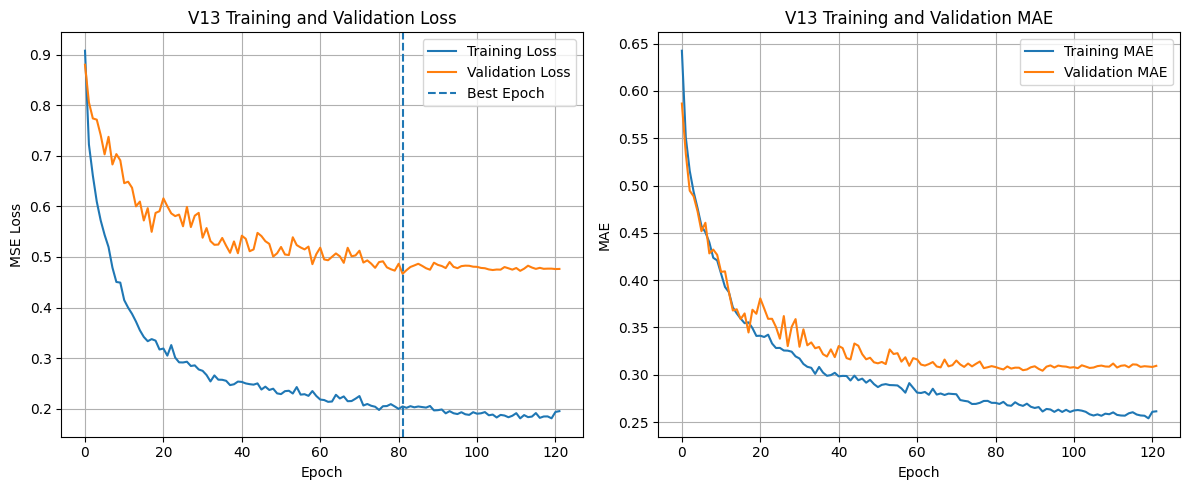


V13 model and scalers saved successfully.


In [ ]:

# AIRFOIL DRAG COEFFICIENT PREDICTION - V13
# Complete pipeline: Loading -> Preprocessing -> Training
# -> Evaluation -> Visualization


import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam


# 1. REPRODUCIBILITY


tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

print("TensorFlow version:", tf.__version__)


# 2. LOAD DATASET SPLITS


train_file = DATA_DIR / "airfoil_train_1000.csv"
val_file = DATA_DIR / "airfoil_validation_1000.csv"
test_file = DATA_DIR / "airfoil_test_1000.csv"

for file in [train_file, val_file, test_file]:
    if not os.path.exists(file):
        raise FileNotFoundError(
            f"{file} not found. Upload the CSV files "
            "to your notebook's working directory."
        )

train_1000 = pd.read_csv(train_file)
val_1000 = pd.read_csv(val_file)
test_1000 = pd.read_csv(test_file)

print("\nDataset dimensions:")
print("Training:", train_1000.shape)
print("Validation:", val_1000.shape)
print("Testing:", test_1000.shape)


# 3. DATA VALIDATION


geometry_cols_1000 = [
    f"geometry_{i:03d}" for i in range(200)
]

feature_cols_1000 = geometry_cols_1000 + ["alpha_deg"]
target_col = "cd"

required_cols = feature_cols_1000 + [target_col, "airfoil"]

for name, df in [
    ("Training", train_1000),
    ("Validation", val_1000),
    ("Testing", test_1000)
]:
    missing = set(required_cols) - set(df.columns)

    if missing:
        raise ValueError(
            f"{name} dataset is missing columns: {missing}"
        )

    if df[required_cols].isnull().any().any():
        raise ValueError(
            f"Missing values found in {name} dataset."
        )

    print(
        f"{name} unique airfoils:",
        df["airfoil"].nunique()
    )

# Check for airfoil overlap
train_ids = set(train_1000["airfoil"])
val_ids = set(val_1000["airfoil"])
test_ids = set(test_1000["airfoil"])

assert train_ids.isdisjoint(val_ids), "Train/validation overlap!"
assert train_ids.isdisjoint(test_ids), "Train/test overlap!"
assert val_ids.isdisjoint(test_ids), "Validation/test overlap!"

print("\nNo airfoil overlap detected.")


# 4. SEPARATE INPUTS AND TARGET


X_train_1000 = train_1000[feature_cols_1000].astype(float)
X_val_1000 = val_1000[feature_cols_1000].astype(float)
X_test_1000 = test_1000[feature_cols_1000].astype(float)

y_train_1000 = train_1000[target_col].astype(float)
y_val_1000 = val_1000[target_col].astype(float)
y_test_1000 = test_1000[target_col].astype(float)


# 5. FEATURE SCALING


input_scaler_1000 = StandardScaler()

X_train_1000_scaled = input_scaler_1000.fit_transform(
    X_train_1000
)

X_val_1000_scaled = input_scaler_1000.transform(
    X_val_1000
)

X_test_1000_scaled = input_scaler_1000.transform(
    X_test_1000
)


# 6. TARGET SCALING


target_scaler_1000 = StandardScaler()

y_train_1000_scaled = target_scaler_1000.fit_transform(
    y_train_1000.to_numpy().reshape(-1, 1)
)

y_val_1000_scaled = target_scaler_1000.transform(
    y_val_1000.to_numpy().reshape(-1, 1)
)

y_test_1000_scaled = target_scaler_1000.transform(
    y_test_1000.to_numpy().reshape(-1, 1)
)

print("\nScaled array dimensions:")
print("X_train:", X_train_1000_scaled.shape)
print("X_val:", X_val_1000_scaled.shape)
print("X_test:", X_test_1000_scaled.shape)
print("y_train:", y_train_1000_scaled.shape)
print("y_val:", y_val_1000_scaled.shape)
print("y_test:", y_test_1000_scaled.shape)


# 7. BUILD V13 MODEL


mlp_v13 = Sequential([
    Input(shape=(201,)),

    Dense(
        128,
        activation="relu",
        kernel_regularizer=l2(0.0001)
    ),

    Dropout(0.20),

    Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(0.0001)
    ),

    Dropout(0.10),

    Dense(1)

], name="MLP_V13")


# 8. COMPILE MODEL


mlp_v13.compile(
    optimizer=Adam(learning_rate=0.0003),
    loss="mse",
    metrics=["mae"]
)

print("\nV13 Model Architecture:")
mlp_v13.summary()


# 9. CALLBACKS


early_stopping_v13 = EarlyStopping(
    monitor="val_loss",
    patience=40,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_v13 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=12,
    min_lr=1e-6,
    verbose=1
)


# 10. TRAIN V13


print("\nStarting V13 training...\n")

history_v13 = mlp_v13.fit(
    X_train_1000_scaled,
    y_train_1000_scaled,

    validation_data=(
        X_val_1000_scaled,
        y_val_1000_scaled
    ),

    epochs=500,
    batch_size=64,

    callbacks=[
        early_stopping_v13,
        reduce_lr_v13
    ],

    verbose=1
)


# 11. EVALUATION FUNCTION


def evaluate_v13(y_true, y_pred, dataset_name):

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    r2 = r2_score(y_true, y_pred)

    print(f"\n{dataset_name} RESULTS")
    print("-" * 40)
    print(f"MAE:  {mae:.8f}")
    print(f"RMSE: {rmse:.8f}")
    print(f"R2:   {r2:.6f}")

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }


# 12. PREDICTIONS


y_train_pred_v13_scaled = mlp_v13.predict(
    X_train_1000_scaled,
    verbose=0
)

y_val_pred_v13_scaled = mlp_v13.predict(
    X_val_1000_scaled,
    verbose=0
)

# Convert predictions back to original Cd units
y_train_pred_v13 = target_scaler_1000.inverse_transform(
    y_train_pred_v13_scaled
)

y_val_pred_v13 = target_scaler_1000.inverse_transform(
    y_val_pred_v13_scaled
)


# 13. EVALUATE TRAINING AND VALIDATION

print("\nMETRICS IN STANDARDIZED TARGET UNITS")

train_metrics_v13 = evaluate_v13(
    y_train_1000_scaled,
    y_train_pred_v13_scaled,
    "TRAINING"
)

val_metrics_v13 = evaluate_v13(
    y_val_1000_scaled,
    y_val_pred_v13_scaled,
    "VALIDATION"
)

print("\nMETRICS IN ORIGINAL Cd UNITS")

train_metrics_v13_original = evaluate_v13(
    y_train_1000,
    y_train_pred_v13.flatten(),
    "TRAINING"
)

val_metrics_v13_original = evaluate_v13(
    y_val_1000,
    y_val_pred_v13.flatten(),
    "VALIDATION"
)


# 14. TRAINING INFORMATION


best_epoch_v13 = (
    np.argmin(history_v13.history["val_loss"]) + 1
)

print("\nTRAINING SUMMARY")
print("=" * 40)
print("Best epoch:", best_epoch_v13)
print("Total epochs:", len(history_v13.history["loss"]))
print("Trainable parameters:",
      mlp_v13.count_params())


# 15. TRAINING HISTORY PLOTS


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(
    history_v13.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_v13.history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    best_epoch_v13 - 1,
    linestyle="--",
    label="Best Epoch"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("V13 Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)

plt.plot(
    history_v13.history["mae"],
    label="Training MAE"
)

plt.plot(
    history_v13.history["val_mae"],
    label="Validation MAE"
)

plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("V13 Training and Validation MAE")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# 16. SAVE MODEL AND SCALERS


mlp_v13.save("airfoil_mlp_v13.keras")

import joblib

joblib.dump(
    input_scaler_1000,
    "input_scaler_v13.pkl"
)

joblib.dump(
    target_scaler_1000,
    "target_scaler_v13.pkl"
)

print("\nV13 model and scalers saved successfully.")

**Result:** validation R² **0.542**, worse than V12. The validation loss stopped improving at epoch 82. Weakening L2 (as V9 already showed) and shrinking the network removed useful capacity without fixing the generalisation gap.

Rather than guessing at more hyperparameters, the next five cells investigate **where** the error comes from.

---
## Diagnostic 1: error by angle of attack and by airfoil

ERROR BY ANGLE OF ATTACK
               mean    median       max  count
alpha_deg                                     
 6.0       0.001315  0.000856  0.039743    145
 5.0       0.001030  0.000689  0.024772    142
-2.0       0.001005  0.000577  0.019550    133
 4.0       0.000831  0.000603  0.013195    139
-1.0       0.000821  0.000569  0.010402    137
 3.0       0.000781  0.000543  0.007040    140
 1.0       0.000766  0.000486  0.005444    142
 2.0       0.000748  0.000542  0.007199    140
 0.0       0.000667  0.000455  0.005710    134

ERROR BY AIRFOIL
airfoil
goe09k       0.011914
e377m        0.004891
eiffel371    0.004867
goe462       0.003912
ea81006      0.003187
as6094       0.003135
goe366       0.002939
fx057816     0.002494
fx082512     0.002366
e63          0.002241
ea61009      0.001776
goe29b       0.001752
goe424       0.001729
goe241       0.001625
as6098       0.001591
Name: absolute_error, dtype: float64


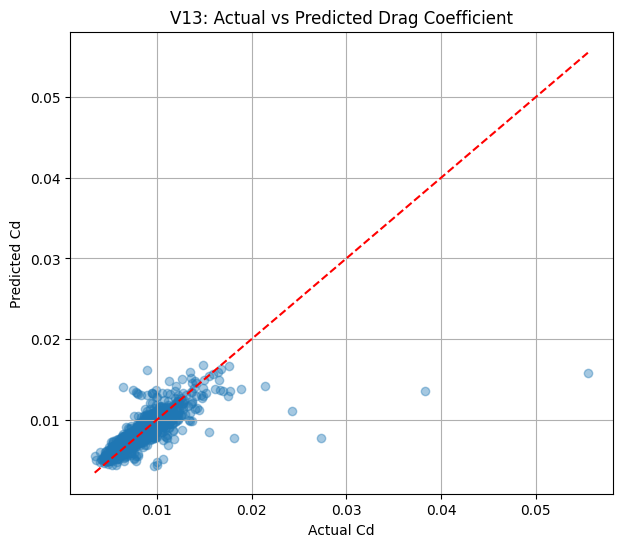

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Predictions in original Cd units
val_pred_original = target_scaler_1000.inverse_transform(
    mlp_v13.predict(X_val_1000_scaled, verbose=0)
).flatten()

# Actual values
val_actual = y_val_1000.to_numpy()

# Create error analysis dataframe
error_df = val_1000[["airfoil", "alpha_deg", "cd"]].copy()

error_df["predicted_cd"] = val_pred_original
error_df["absolute_error"] = np.abs(
    error_df["cd"] - error_df["predicted_cd"]
)

# Error by angle of attack
print("ERROR BY ANGLE OF ATTACK")

print(
    error_df.groupby("alpha_deg")["absolute_error"]
    .agg(["mean", "median", "max", "count"])
    .sort_values("mean", ascending=False)
)

# Error by airfoil
print("\nERROR BY AIRFOIL")

print(
    error_df.groupby("airfoil")["absolute_error"]
    .mean()
    .sort_values(ascending=False)
    .head(15)
)

# Actual vs predicted
plt.figure(figsize=(7, 6))
plt.scatter(
    val_actual,
    val_pred_original,
    alpha=0.4
)

limits = [
    min(val_actual.min(), val_pred_original.min()),
    max(val_actual.max(), val_pred_original.max())
]

plt.plot(limits, limits, "r--")
plt.xlabel("Actual Cd")
plt.ylabel("Predicted Cd")
plt.title("V13: Actual vs Predicted Drag Coefficient")
plt.grid(True)
plt.show()

The error is concentrated: α = 5–6° and α = −2° (the edges of the drag bucket) have the largest errors, and one airfoil, **goe09k**, has a mean error ~2.5× larger than the next worst airfoil.

## Diagnostic 2: the worst predictions, GOE09K, and the high-drag tail

In [ ]:

# V14 PREPARATION - HIGH ERROR INVESTIGATION


# 1. Inspect the 20 worst predictions
print("TOP 20 WORST PREDICTIONS")
display(
    error_df.sort_values(
        "absolute_error", ascending=False
    ).head(20)
)

# 2. Investigate goe09k
print("\nGOE09K ANALYSIS")

goe09k_data = error_df[
    error_df["airfoil"] == "goe09k"
]

display(goe09k_data.sort_values(
    "absolute_error", ascending=False
))

print("\nGOE09K summary:")
print(goe09k_data[
    ["cd", "predicted_cd", "absolute_error"]
].describe())

# 3. Understand target distribution
print("\nACTUAL Cd DISTRIBUTION")

print(
    error_df["cd"].describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

# 4. Investigate high-drag predictions
high_drag = error_df[
    error_df["cd"] >= error_df["cd"].quantile(0.95)
]

print("\nTOP 5% HIGH-DRAG OBSERVATIONS")
print("Count:", len(high_drag))
print("Mean actual Cd:", high_drag["cd"].mean())
print("Mean predicted Cd:", high_drag["predicted_cd"].mean())
print("Mean absolute error:", high_drag["absolute_error"].mean())

# 5. Error distribution by airfoil
print("\nAIRFOIL SAMPLE COUNTS")

display(
    error_df.groupby("airfoil")
    .agg(
        samples=("cd", "count"),
        mean_error=("absolute_error", "mean"),
        max_error=("absolute_error", "max")
    )
    .sort_values("mean_error", ascending=False)
    .head(15)
)

TOP 20 WORST PREDICTIONS


,airfoil,alpha_deg,cd,predicted_cd,absolute_error
668,goe09k,6.0,0.05549,0.015747,0.039743
667,goe09k,5.0,0.03835,0.013578,0.024772
146,as6094,-2.0,0.02728,0.007730,0.019550
666,goe09k,4.0,0.02427,0.011075,0.013195
154,as6098,-1.0,0.01812,0.007718,0.010402
422,e63,6.0,0.00641,0.014013,0.007603
812,goe366,-2.0,0.02139,0.014165,0.007225
332,e377m,2.0,0.00893,0.016129,0.007199
665,goe09k,3.0,0.01556,0.008520,0.007040
507,eiffel371,-1.0,0.00753,0.013725,0.006195



GOE09K ANALYSIS


,airfoil,alpha_deg,cd,predicted_cd,absolute_error
668,goe09k,6.0,0.05549,0.015747,0.039743
667,goe09k,5.0,0.03835,0.013578,0.024772
666,goe09k,4.0,0.02427,0.011075,0.013195
665,goe09k,3.0,0.01556,0.008520,0.007040
661,goe09k,-2.0,0.01062,0.005195,0.005425
664,goe09k,1.0,0.00345,0.005481,0.002031
662,goe09k,-1.0,0.00656,0.004919,0.001641
663,goe09k,0.0,0.00355,0.005012,0.001462



GOE09K summary:
             cd  predicted_cd  absolute_error
count  8.000000      8.000000        8.000000
mean   0.019731      0.008691        0.011914
std    0.018696      0.004304        0.013731
min    0.003450      0.004919        0.001462
25%    0.005808      0.005150        0.001933
50%    0.013090      0.007000        0.006232
75%    0.027790      0.011701        0.016089
max    0.055490      0.015747        0.039743

ACTUAL Cd DISTRIBUTION
count    1252.000000
mean        0.008416
std         0.002845
min         0.003450
50%         0.008090
75%         0.009490
90%         0.011119
95%         0.012390
99%         0.016594
max         0.055490
Name: cd, dtype: float64

TOP 5% HIGH-DRAG OBSERVATIONS
Count: 64
Mean actual Cd: 0.015806249999999997
Mean predicted Cd: 0.0127611095
Mean absolute error: 0.0033922683026106097

AIRFOIL SAMPLE COUNTS


,samples,mean_error,max_error
airfoil,,,
goe09k,8,0.011914,0.039743
e377m,3,0.004891,0.007199
eiffel371,8,0.004867,0.006195
goe462,4,0.003912,0.005080
ea81006,9,0.003187,0.005566
as6094,8,0.003135,0.019550
goe366,6,0.002939,0.007225
fx057816,8,0.002494,0.003304
fx082512,9,0.002366,0.004338


GOE09K's drag rises steeply from α = 3° (0.016) to α = 6° (0.055), and the model predicts only about 0.016 at 6°. Across the whole validation set, the top 5% highest-drag points are systematically **under-predicted** (mean predicted 0.0128 vs actual 0.0158).

## Diagnostic 3: how is $C_d$ distributed across the splits?

CD DISTRIBUTION ACROSS DATA SPLITS

Training
Samples: 5744
Mean Cd: 0.008458464484679665
Median Cd: 0.0081
95th percentile: 0.012668499999999996
99th percentile: 0.018865499999999955
Maximum Cd: 0.03852

Validation
Samples: 1252
Mean Cd: 0.00841591054313099
Median Cd: 0.00809
95th percentile: 0.01239
99th percentile: 0.016593700000000003
Maximum Cd: 0.05549

Testing
Samples: 1255
Mean Cd: 0.008783737051792827
Median Cd: 0.0082
95th percentile: 0.012503
99th percentile: 0.019629200000000038
Maximum Cd: 0.06194

HIGH-DRAG OBSERVATION COUNTS

Training
Cd > 0.015: 130
Cd > 0.02: 52
Cd > 0.03: 17
Cd > 0.04: 0

Validation
Cd > 0.015: 20
Cd > 0.02: 5
Cd > 0.03: 2
Cd > 0.04: 1

Testing
Cd > 0.015: 32
Cd > 0.02: 13
Cd > 0.03: 8
Cd > 0.04: 8

VALIDATION HIGH-DRAG OBSERVATIONS


,airfoil,alpha_deg,cd
668,goe09k,6.0,0.05549
667,goe09k,5.0,0.03835
146,as6094,-2.0,0.02728
666,goe09k,4.0,0.02427
812,goe366,-2.0,0.02139



TRAINING HIGH-DRAG OBSERVATIONS


,airfoil,alpha_deg,cd
1619,e379,-2.0,0.03852
4880,goe570,6.0,0.03737
5400,griffith30SymSuction,0.0,0.03654
5399,griffith30SymSuction,-1.0,0.03640
5403,griffith30SymSuction,4.0,0.03637
5401,griffith30SymSuction,2.0,0.03586
5398,griffith30SymSuction,-2.0,0.03586
5402,griffith30SymSuction,3.0,0.03570
5404,griffith30SymSuction,5.0,0.03524
5405,griffith30SymSuction,6.0,0.03451


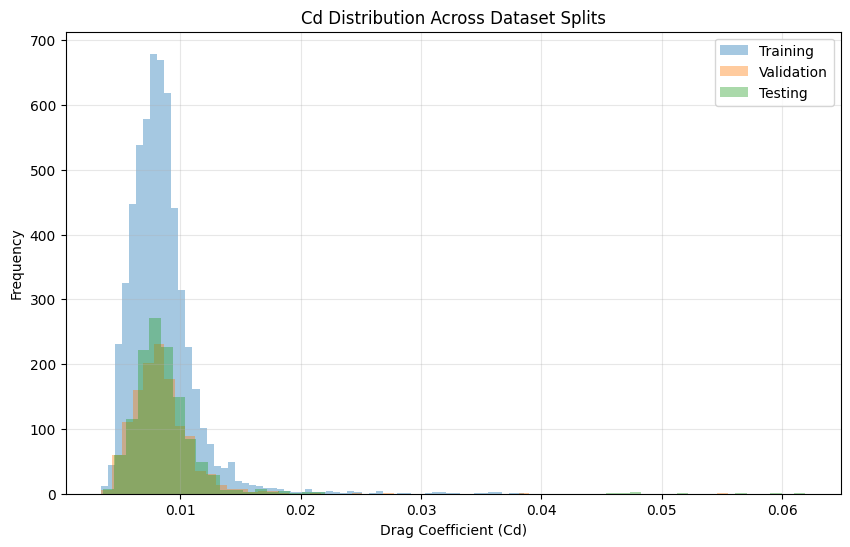

In [ ]:
# V14 PREPARATION: INVESTIGATE HIGH-DRAG DATA DISTRIBUTION

datasets = {
    "Training": train_1000,
    "Validation": val_1000,
    "Testing": test_1000
}

# 1. Compare Cd distributions
print("CD DISTRIBUTION ACROSS DATA SPLITS")

for name, df in datasets.items():
    print(f"\n{name}")
    print("Samples:", len(df))
    print("Mean Cd:", df["cd"].mean())
    print("Median Cd:", df["cd"].median())
    print("95th percentile:", df["cd"].quantile(0.95))
    print("99th percentile:", df["cd"].quantile(0.99))
    print("Maximum Cd:", df["cd"].max())

# 2. Count high-drag observations
thresholds = [0.015, 0.020, 0.030, 0.040]

print("\nHIGH-DRAG OBSERVATION COUNTS")

for name, df in datasets.items():
    print(f"\n{name}")

    for threshold in thresholds:
        count = (df["cd"] > threshold).sum()
        print(f"Cd > {threshold}: {count}")

# 3. Inspect all validation observations above 0.02
print("\nVALIDATION HIGH-DRAG OBSERVATIONS")

high_drag_validation = val_1000[
    val_1000["cd"] > 0.02
].sort_values("cd", ascending=False)

display(
    high_drag_validation[
        ["airfoil", "alpha_deg", "cd"]
    ]
)

# 4. Inspect high-drag observations in training
print("\nTRAINING HIGH-DRAG OBSERVATIONS")

high_drag_training = train_1000[
    train_1000["cd"] > 0.02
].sort_values("cd", ascending=False)

display(
    high_drag_training[
        ["airfoil", "alpha_deg", "cd"]
    ].head(30)
)

# 5. Plot Cd distributions
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for name, df in datasets.items():
    plt.hist(
        df["cd"],
        bins=60,
        alpha=0.4,
        label=name
    )

plt.xlabel("Drag Coefficient (Cd)")
plt.ylabel("Frequency")
plt.title("Cd Distribution Across Dataset Splits")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The target is **skewed to the right**: the median is ~0.008, but a long tail reaches 0.04–0.06. Only 52 training rows (0.9%) have $C_d$ > 0.02. A model trained with plain MSE on the standardised target is dominated by the dense middle of the distribution and treats the tail as rare noise.

## Diagnostic 4: does validation require extrapolating beyond the training range?

In [ ]:

# DIAGNOSTIC: TARGET EXTRAPOLATION


train_min = train_1000["cd"].min()
train_max = train_1000["cd"].max()

print("Training Cd range:", train_min, "to", train_max)

# Validation observations outside training range
outside_val = val_1000[
    (val_1000["cd"] < train_min) |
    (val_1000["cd"] > train_max)
]

print("\nValidation observations outside training range:")
print(len(outside_val))

display(
    outside_val[
        ["airfoil", "alpha_deg", "cd"]
    ].sort_values("cd", ascending=False)
)

# Compare maximum Cd by angle
print("\nMAXIMUM Cd BY ANGLE")

print(
    train_1000.groupby("alpha_deg")["cd"].max()
    .rename("Training")
    .to_frame()
    .join(
        val_1000.groupby("alpha_deg")["cd"].max()
        .rename("Validation")
    )
)

Training Cd range: 0.0034 to 0.03852

Validation observations outside training range:
1


,airfoil,alpha_deg,cd
668,goe09k,6.0,0.05549



MAXIMUM Cd BY ANGLE
           Training  Validation
alpha_deg                      
-2.0        0.03852     0.02728
-1.0        0.03640     0.01812
 0.0        0.03654     0.01401
 1.0        0.02429     0.01770
 2.0        0.03586     0.01698
 3.0        0.03570     0.01666
 4.0        0.03637     0.02427
 5.0        0.03524     0.03835
 6.0        0.03737     0.05549


One validation point (GOE09K, α = 6°, $C_d$ = 0.0555) lies **above the largest $C_d$ in the whole training set** (0.0385). No regression model can be expected to reach it reliably.

## Diagnostic 5: confirm the split is clean

In [ ]:
#AIRFOIL OVERLAP CHECK

train_airfoils = set(train_1000["airfoil"].unique())
val_airfoils = set(val_1000["airfoil"].unique())
test_airfoils = set(test_1000["airfoil"].unique())

print("Unique airfoils:")
print("Training:", len(train_airfoils))
print("Validation:", len(val_airfoils))
print("Testing:", len(test_airfoils))

print("\nAirfoil overlap:")
print("Train-Val:", len(train_airfoils & val_airfoils))
print("Train-Test:", len(train_airfoils & test_airfoils))
print("Val-Test:", len(val_airfoils & test_airfoils))

print("\nGOE09K membership:")
print("Training:", "goe09k" in train_airfoils)
print("Validation:", "goe09k" in val_airfoils)
print("Testing:", "goe09k" in test_airfoils)

Unique airfoils:
Training: 690
Validation: 149
Testing: 149

Airfoil overlap:
Train-Val: 0
Train-Test: 0
Val-Test: 0

GOE09K membership:
Training: False
Validation: True
Testing: False


No airfoil appears in more than one split, and GOE09K appears only in validation, so the problem is genuine extrapolation, not leakage.

**Conclusions that shaped V14 and V15:**
1. The target is skewed and drag errors are naturally relative (a 0.001 error matters far more at $C_d$ = 0.005 than at 0.05), so model $\log C_d$ (**V14**).
2. The high-drag tail is under-represented, so give it more weight in the loss (**V15**).

---
## V14: log-transformed target

**What:** train on standardised $\log C_d$ and invert with exp. Back to the V12 architecture (256-128, L2 1e-3, dropout 0.15), now with ReduceLROnPlateau.

**Why:** the log compresses the long tail, makes the target distribution close to symmetric, and turns the loss into a *relative*-error loss, which matches how drag errors are judged. Predictions are also guaranteed to be positive.

In [ ]:
# V14 - LOG TRANSFORMED TARGET MLP

import numpy as np
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

# Reproducibility
tf.keras.utils.set_random_seed(42)

# ------------------------------------------------------------
# 1. LOG TRANSFORM TARGET
# ------------------------------------------------------------

# Check positivity
assert (y_train_1000 > 0).all()
assert (y_val_1000 > 0).all()

# Natural logarithm of Cd
y_train_v14 = np.log(
    y_train_1000.to_numpy().reshape(-1, 1)
)

y_val_v14 = np.log(
    y_val_1000.to_numpy().reshape(-1, 1)
)

# Standardize log-transformed target using training statistics
log_mean_v14 = y_train_v14.mean()
log_std_v14 = y_train_v14.std()

y_train_v14_scaled = (
    y_train_v14 - log_mean_v14
) / log_std_v14

y_val_v14_scaled = (
    y_val_v14 - log_mean_v14
) / log_std_v14

# ------------------------------------------------------------
# 2. BUILD MODEL
# ------------------------------------------------------------

mlp_v14 = Sequential([
    Input(shape=(201,)),

    Dense(
        256,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    Dropout(0.15),

    Dense(
        128,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    Dense(1)
], name="MLP_V14_LogTarget")


# 3. COMPILE


mlp_v14.compile(
    optimizer=Adam(learning_rate=0.0003),
    loss="mse",
    metrics=["mae"]
)


# 4. CALLBACKS


early_stopping_v14 = EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_v14 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=12,
    min_lr=1e-6,
    verbose=1
)


# 5. MODEL SUMMARY


mlp_v14.summary()


# 6. TRAIN


history_v14 = mlp_v14.fit(
    X_train_1000_scaled,
    y_train_v14_scaled,
    validation_data=(
        X_val_1000_scaled,
        y_val_v14_scaled
    ),
    epochs=500,
    batch_size=64,
    callbacks=[
        early_stopping_v14,
        reduce_lr_v14
    ],
    verbose=1
)


# V14 - EVALUATION


from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict standardized log Cd
train_pred_log_v14 = mlp_v14.predict(
    X_train_1000_scaled,
    verbose=0
)

val_pred_log_v14 = mlp_v14.predict(
    X_val_1000_scaled,
    verbose=0
)

# Reverse standardization and logarithm
train_pred_v14 = np.exp(
    train_pred_log_v14 * log_std_v14 + log_mean_v14
).flatten()

val_pred_v14 = np.exp(
    val_pred_log_v14 * log_std_v14 + log_mean_v14
).flatten()

# Actual Cd
train_actual_v14 = y_train_1000.to_numpy()
val_actual_v14 = y_val_1000.to_numpy()

# Evaluation function
def evaluate_v14(y_true, y_pred, name):

    print(f"\n{name} RESULTS")
    print("-" * 40)

    print("MAE:", mean_absolute_error(y_true, y_pred))

    print(
        "RMSE:",
        np.sqrt(mean_squared_error(y_true, y_pred))
    )

    print("R2:", r2_score(y_true, y_pred))


# Evaluate
evaluate_v14(
    train_actual_v14,
    train_pred_v14,
    "TRAINING"
)

evaluate_v14(
    val_actual_v14,
    val_pred_v14,
    "VALIDATION"
)

print("\nTRAINING SUMMARY")
print("=" * 40)

print(
    "Best epoch:",
    np.argmin(history_v14.history["val_loss"]) + 1
)

print(
    "Total epochs:",
    len(history_v14.history["loss"])
)

print(
    "Trainable parameters:",
    mlp_v14.count_params()
)

Model: "MLP_V14_LogTarget"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 256)            │        51,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 84,737 (331.00 KB)

 Trainable params: 84,737 (331.00 KB)

 Non-trainable params: 0 (0.00 B)

[... per-epoch training log trimmed: 287 epochs run; final epoch shown below ...]
Epoch 160: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
Epoch 190: ReduceLROnPlateau reducing learning rate to 7.500000356230885e-05.
Epoch 202: ReduceLROnPlateau reducing learning rate to 3.7500001781154424e-05.
Epoch 225: ReduceLROnPlateau reducing learning rate to 1.8750000890577212e-05.
Epoch 269: ReduceLROnPlateau reducing learning rate to 9.375000445288606e-06.
Epoch 281: ReduceLROnPlateau reducing learning rate to 4.687500222644303e-06.
Epoch 287/500
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1029 - mae: 0.1659 - val_loss: 0.2835 - val_mae: 0.2927 - learning_rate: 4.6875e-06
Epoch 287: early stopping
Restoring model weights from the end of the best epoch: 257.



TRAINING RESULTS
----------------------------------------
MAE: 0.0003533739603825504
RMSE: 0.0006058232949878556
R2: 0.956145735113803

VALIDATION RESULTS
----------------------------------------
MAE: 0.0007459519480154622
RMSE: 0.0017248946644773133
R2: 0.6321825159840124

TRAINING SUMMARY
Best epoch: 257
Total epochs: 287
Trainable parameters: 84737


**Result:** validation R² **0.632**, MAE **0.000746** (the lowest so far on this dataset). Training R² is 0.956, so the generalisation gap is still large.

### V14 vs V13 comparison

GOE09K: V13 vs V14


,alpha_deg,cd,predicted_v13,predicted_v14,error_v13,error_v14
661,-2.0,0.01062,0.005195,0.005717,0.005425,0.004903
662,-1.0,0.00656,0.004919,0.004548,0.001641,0.002012
663,0.0,0.00355,0.005012,0.003767,0.001462,0.000217
664,1.0,0.00345,0.005481,0.004100,0.002031,0.000650
665,3.0,0.01556,0.008520,0.008766,0.007040,0.006794
666,4.0,0.02427,0.011075,0.012575,0.013195,0.011695
667,5.0,0.03835,0.013578,0.016610,0.024772,0.021740
668,6.0,0.05549,0.015747,0.020814,0.039743,0.034676



HIGH DRAG OBSERVATIONS: V13 vs V14
Number of observations: 20
V13 MAE: 0.007515180502407253
V14 MAE: 0.006524261913157815

OVERALL VALIDATION MAE
V13: 0.000887298712026292
V14: 0.0007459519480154622


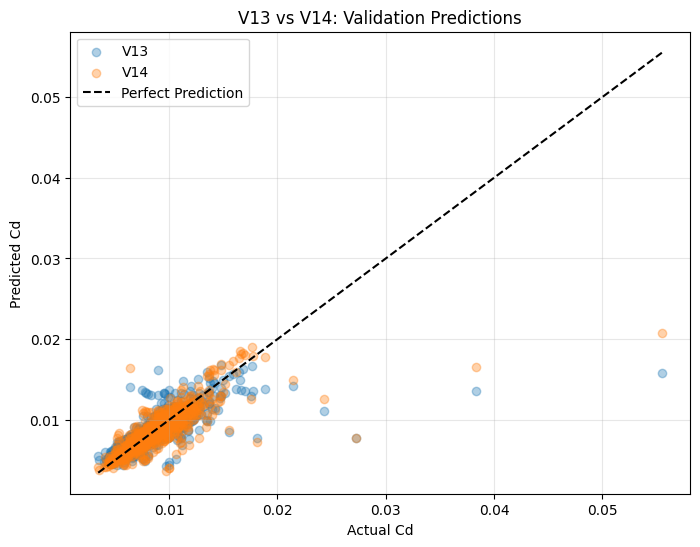

In [ ]:
# V14 vs V13 - DETAILED VALIDATION COMPARISON


comparison_v14 = val_1000[
    ["airfoil", "alpha_deg", "cd"]
].copy()

comparison_v14["predicted_v13"] = val_pred_original
comparison_v14["predicted_v14"] = val_pred_v14

comparison_v14["error_v13"] = np.abs(
    comparison_v14["cd"] -
    comparison_v14["predicted_v13"]
)

comparison_v14["error_v14"] = np.abs(
    comparison_v14["cd"] -
    comparison_v14["predicted_v14"]
)

# GOE09K comparison
print("GOE09K: V13 vs V14")

display(
    comparison_v14[
        comparison_v14["airfoil"] == "goe09k"
    ][[
        "alpha_deg",
        "cd",
        "predicted_v13",
        "predicted_v14",
        "error_v13",
        "error_v14"
    ]]
)

# High drag observations
print("\nHIGH DRAG OBSERVATIONS: V13 vs V14")

high_drag_v14 = comparison_v14[
    comparison_v14["cd"] > 0.015
]

print("Number of observations:", len(high_drag_v14))

print(
    "V13 MAE:",
    high_drag_v14["error_v13"].mean()
)

print(
    "V14 MAE:",
    high_drag_v14["error_v14"].mean()
)

# Overall comparison
print("\nOVERALL VALIDATION MAE")

print("V13:", comparison_v14["error_v13"].mean())
print("V14:", comparison_v14["error_v14"].mean())

# Actual vs predicted plot
plt.figure(figsize=(8, 6))

plt.scatter(
    comparison_v14["cd"],
    comparison_v14["predicted_v13"],
    alpha=0.35,
    label="V13"
)

plt.scatter(
    comparison_v14["cd"],
    comparison_v14["predicted_v14"],
    alpha=0.35,
    label="V14"
)

limits = [
    min(comparison_v14["cd"].min(),
        comparison_v14["predicted_v13"].min(),
        comparison_v14["predicted_v14"].min()),

    max(comparison_v14["cd"].max(),
        comparison_v14["predicted_v13"].max(),
        comparison_v14["predicted_v14"].max())
]

plt.plot(limits, limits, "k--", label="Perfect Prediction")

plt.xlabel("Actual Cd")
plt.ylabel("Predicted Cd")
plt.title("V13 vs V14: Validation Predictions")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The log target improves GOE09K at low α and reduces high-drag MAE (0.0075 → 0.0065), but at α = 6° the prediction (0.021) is still far below the true 0.055.

---
## V15: log target + sample weights for high drag

**What:** keep V14 and weight each training row by its $C_d$ in the loss: weight 1.5 for $C_d$ ≥ 0.010, 2.0 for ≥ 0.015 and 3.0 for ≥ 0.020 (about 18% of rows get extra weight).

**Why:** the log target alone still lets the rare high-drag rows count little in the total loss; up-weighting them should pull the model toward the tail without discarding any data.

In [ ]:
import numpy as np

# V15: Sample weighting based on original Cd values

def assign_drag_weights(cd_values):

    weights = np.ones(len(cd_values))

    weights[cd_values >= 0.010] = 1.5
    weights[cd_values >= 0.015] = 2.0
    weights[cd_values >= 0.020] = 3.0

    return weights


# Generate weights from original training Cd
sample_weights_v15 = assign_drag_weights(
    train_1000["cd"].to_numpy()
)

# Inspect weights
print("V15 Sample Weight Distribution")

for weight in np.unique(sample_weights_v15):
    count = np.sum(sample_weights_v15 == weight)

    print(
        f"Weight {weight}: {count} observations "
        f"({count / len(sample_weights_v15) * 100:.2f}%)"
    )

print("\nTotal observations:", len(sample_weights_v15))
print("Average weight:", sample_weights_v15.mean())


# V15 - LOG TARGET + SAMPLE WEIGHTED MLP


import numpy as np
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam


# 1. REPRODUCIBILITY


tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)


# 2. LOG TRANSFORM TARGET


assert (y_train_1000 > 0).all()
assert (y_val_1000 > 0).all()

y_train_v15 = np.log(
    y_train_1000.to_numpy().reshape(-1, 1)
)

y_val_v15 = np.log(
    y_val_1000.to_numpy().reshape(-1, 1)
)

# Standardize using training statistics only
log_mean_v15 = y_train_v15.mean()
log_std_v15 = y_train_v15.std()

y_train_v15_scaled = (
    y_train_v15 - log_mean_v15
) / log_std_v15

y_val_v15_scaled = (
    y_val_v15 - log_mean_v15
) / log_std_v15


# 3. VERIFY SAMPLE WEIGHTS


assert len(sample_weights_v15) == len(X_train_1000_scaled)
assert np.isfinite(sample_weights_v15).all()
assert (sample_weights_v15 > 0).all()

print("Sample weights verified:", len(sample_weights_v15))


# 4. BUILD MODEL


mlp_v15 = Sequential([
    Input(shape=(201,)),

    Dense(
        256,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    Dropout(0.15),

    Dense(
        128,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    Dense(1)

], name="MLP_V15_Weighted_LogTarget")


# 5. COMPILE


mlp_v15.compile(
    optimizer=Adam(learning_rate=0.0003),
    loss="mse",
    metrics=["mae"]
)


# 6. CALLBACKS


early_stopping_v15 = EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_v15 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=12,
    min_lr=1e-6,
    verbose=1
)


# 7. MODEL SUMMARY


mlp_v15.summary()


# 8. TRAIN WITH SAMPLE WEIGHTS


history_v15 = mlp_v15.fit(

    X_train_1000_scaled,

    y_train_v15_scaled,

    sample_weight=sample_weights_v15,

    validation_data=(
        X_val_1000_scaled,
        y_val_v15_scaled
    ),

    epochs=500,

    batch_size=64,

    callbacks=[
        early_stopping_v15,
        reduce_lr_v15
    ],

    verbose=1
)


# 9. TRAINING SUMMARY

best_epoch_v15 = (
    np.argmin(history_v15.history["val_loss"]) + 1
)

print("\nV15 TRAINING SUMMARY")
print("=" * 45)

print("Best epoch:", best_epoch_v15)
print("Total epochs:", len(history_v15.history["loss"]))
print("Trainable parameters:",
      mlp_v15.count_params())

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# V15 validation predictions
pred_v15_scaled = mlp_v15.predict(
    X_val_1000_scaled,
    verbose=0
)

# Reverse standardization and log transformation
pred_v15_log = (
    pred_v15_scaled * log_std_v15
    + log_mean_v15
)

val_pred_v15 = np.exp(pred_v15_log).flatten()

actual_v15 = y_val_1000.to_numpy()

# Overall metrics
mae_v15 = mean_absolute_error(actual_v15, val_pred_v15)

rmse_v15 = np.sqrt(
    mean_squared_error(actual_v15, val_pred_v15)
)

r2_v15 = r2_score(actual_v15, val_pred_v15)

print("V15 VALIDATION RESULTS")
print("=" * 45)
print("MAE:", mae_v15)
print("RMSE:", rmse_v15)
print("R2:", r2_v15)

# High-drag evaluation
high_drag_mask = actual_v15 > 0.015

high_drag_mae_v15 = mean_absolute_error(
    actual_v15[high_drag_mask],
    val_pred_v15[high_drag_mask]
)

print("\nHIGH-DRAG VALIDATION RESULTS")
print("=" * 45)
print("Observations:", high_drag_mask.sum())
print("High-drag MAE:", high_drag_mae_v15)

# Prediction range
print("\nPREDICTION RANGE")
print("Actual maximum Cd:", actual_v15.max())
print("Predicted maximum Cd:", val_pred_v15.max())

V15 Sample Weight Distribution
Weight 1.0: 4697 observations (81.77%)
Weight 1.5: 915 observations (15.93%)
Weight 2.0: 80 observations (1.39%)
Weight 3.0: 52 observations (0.91%)

Total observations: 5744
Average weight: 1.1116817548746518


Sample weights verified: 5744


Model: "MLP_V15_Weighted_LogTarget"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        51,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 84,737 (331.00 KB)

 Trainable params: 84,737 (331.00 KB)

 Non-trainable params: 0 (0.00 B)

[... per-epoch training log trimmed: 309 epochs run; final epoch shown below ...]
Epoch 183: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
Epoch 195: ReduceLROnPlateau reducing learning rate to 7.500000356230885e-05.
Epoch 216: ReduceLROnPlateau reducing learning rate to 3.7500001781154424e-05.
Epoch 272: ReduceLROnPlateau reducing learning rate to 1.8750000890577212e-05.
Epoch 291: ReduceLROnPlateau reducing learning rate to 9.375000445288606e-06.
Epoch 303: ReduceLROnPlateau reducing learning rate to 4.687500222644303e-06.
Epoch 309/500
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1441 - mae: 0.1731 - val_loss: 0.3100 - val_mae: 0.2995 - learning_rate: 4.6875e-06
Epoch 309: early stopping
Restoring model weights from the end of the best epoch: 279.

V15 TRAINING SUMMARY
Best epoch: 279
Total epochs: 309
Trainable parameters: 84737


V15 VALIDATION RESULTS
MAE: 0.0007587822086027091
RMSE: 0.0016716846793699575
R2: 0.6545255482783214

HIGH-DRAG VALIDATION RESULTS
Observations: 20
High-drag MAE: 0.006175569152517743

PREDICTION RANGE
Actual maximum Cd: 0.05549
Predicted maximum Cd: 0.023446821077203858


**Result:** validation R² **0.6545** (MAE 0.000759, RMSE 0.001672). This is the best single-run R² of V12–V17 and became the **benchmark**. High-drag MAE improved to 0.0062.

### V14 vs V15 comparison

In [ ]:
# V14 vs V15 - GOE09K AND HIGH DRAG ANALYSIS


comparison_v15 = val_1000[
    ["airfoil", "alpha_deg", "cd"]
].copy()

comparison_v15["predicted_v14"] = val_pred_v14
comparison_v15["predicted_v15"] = val_pred_v15

comparison_v15["error_v14"] = np.abs(
    comparison_v15["cd"] -
    comparison_v15["predicted_v14"]
)

comparison_v15["error_v15"] = np.abs(
    comparison_v15["cd"] -
    comparison_v15["predicted_v15"]
)

# GOE09K analysis
print("GOE09K: V14 vs V15")

goe09k_v15 = comparison_v15[
    comparison_v15["airfoil"] == "goe09k"
]

display(goe09k_v15)

print("\nGOE09K MAE")
print("V14:", goe09k_v15["error_v14"].mean())
print("V15:", goe09k_v15["error_v15"].mean())

# High drag analysis
high_drag_v15 = comparison_v15[
    comparison_v15["cd"] > 0.015
]

print("\nHIGH DRAG COMPARISON")
print("V14 MAE:", high_drag_v15["error_v14"].mean())
print("V15 MAE:", high_drag_v15["error_v15"].mean())

# Worst 10 predictions
print("\nTOP 10 WORST V15 PREDICTIONS")

display(
    comparison_v15.sort_values(
        "error_v15",
        ascending=False
    ).head(10)
)

# Compare errors across all observations
print("\nOVERALL ERROR COMPARISON")
print("V14:", comparison_v15["error_v14"].mean())
print("V15:", comparison_v15["error_v15"].mean())

GOE09K: V14 vs V15


,airfoil,alpha_deg,cd,predicted_v14,predicted_v15,error_v14,error_v15
661,goe09k,-2.0,0.01062,0.005717,0.005351,0.004903,0.005269
662,goe09k,-1.0,0.00656,0.004548,0.004440,0.002012,0.002120
663,goe09k,0.0,0.00355,0.003767,0.003877,0.000217,0.000327
664,goe09k,1.0,0.00345,0.004100,0.004428,0.000650,0.000978
665,goe09k,3.0,0.01556,0.008766,0.009009,0.006794,0.006551
666,goe09k,4.0,0.02427,0.012575,0.013181,0.011695,0.011089
667,goe09k,5.0,0.03835,0.016610,0.018139,0.021740,0.020211
668,goe09k,6.0,0.05549,0.020814,0.023447,0.034676,0.032043



GOE09K MAE
V14: 0.010335767976964767
V15: 0.009823450733281091

HIGH DRAG COMPARISON
V14 MAE: 0.006524261913157815
V15 MAE: 0.006175569152517743

TOP 10 WORST V15 PREDICTIONS


,airfoil,alpha_deg,cd,predicted_v14,predicted_v15,error_v14,error_v15
668,goe09k,6.0,0.05549,0.020814,0.023447,0.034676,0.032043
667,goe09k,5.0,0.03835,0.016610,0.018139,0.021740,0.020211
146,as6094,-2.0,0.02728,0.007757,0.007344,0.019523,0.019936
666,goe09k,4.0,0.02427,0.012575,0.013181,0.011695,0.011089
154,as6098,-1.0,0.01812,0.007254,0.007135,0.010866,0.010985
422,e63,6.0,0.00641,0.016484,0.016071,0.010074,0.009661
665,goe09k,3.0,0.01556,0.008766,0.009009,0.006794,0.006551
476,ea81006,-1.0,0.00999,0.004040,0.003984,0.005950,0.006006
477,ea81006,0.0,0.00974,0.003717,0.003749,0.006023,0.005991
478,ea81006,1.0,0.00999,0.003986,0.004032,0.006004,0.005958



OVERALL ERROR COMPARISON
V14: 0.0007459519480154622
V15: 0.0007587822086027091


Weighting nudges the high-drag predictions upward (GOE09K at 6°: 0.021 → 0.023), but the dominant error is unchanged. The overall MAE is slightly *worse* than V14's, so the gain in R² comes from a few large points.

---
## V16: add α² and α³ as inputs

**What:** V15 plus two polynomial angle features (203 inputs).

**Why:** drag grows nonlinearly with α near the edges of the drag bucket, where the errors were largest; explicit powers of α might make that curvature easier to learn.

In [ ]:
# V16 - POLYNOMIAL ANGLE FEATURE ENGINEERING
# Retains V15 log target and sample weighting

import numpy as np
import tensorflow as tf

from sklearn.preprocessing import StandardScaler

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

tf.keras.utils.set_random_seed(42)


# 1. FEATURE ENGINEERING


X_train_v16 = X_train_1000.copy()
X_val_v16 = X_val_1000.copy()

# Polynomial angle features
X_train_v16["alpha_squared"] = (
    X_train_v16["alpha_deg"] ** 2
)

X_train_v16["alpha_cubed"] = (
    X_train_v16["alpha_deg"] ** 3
)

X_val_v16["alpha_squared"] = (
    X_val_v16["alpha_deg"] ** 2
)

X_val_v16["alpha_cubed"] = (
    X_val_v16["alpha_deg"] ** 3
)


# 2. SCALE INPUT FEATURES


scaler_v16 = StandardScaler()

X_train_v16_scaled = scaler_v16.fit_transform(
    X_train_v16
)

X_val_v16_scaled = scaler_v16.transform(
    X_val_v16
)

print("V16 Training shape:", X_train_v16_scaled.shape)
print("V16 Validation shape:", X_val_v16_scaled.shape)


# 3. RETAIN V15 LOG-TRANSFORMED TARGET


y_train_v16_scaled = y_train_v14_scaled
y_val_v16_scaled = y_val_v14_scaled


# 4. RETAIN V15 SAMPLE WEIGHTING


cd_train_v16 = y_train_1000.to_numpy()

sample_weights_v16 = np.select(
    [
        cd_train_v16 >= 0.020,
        cd_train_v16 >= 0.015,
        cd_train_v16 >= 0.010
    ],
    [
        3.0,
        2.0,
        1.5
    ],
    default=1.0
)

print("\nSample weights:")
print("Average:", sample_weights_v16.mean())


# 5. BUILD MODEL


mlp_v16 = Sequential([
    Input(shape=(203,)),

    Dense(
        256,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    Dropout(0.15),

    Dense(
        128,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    Dense(1)
], name="MLP_V16_PolynomialAlpha")


# 6. COMPILE


mlp_v16.compile(
    optimizer=Adam(learning_rate=0.0003),
    loss="mse",
    metrics=["mae"]
)


# 7. CALLBACKS


early_stopping_v16 = EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_v16 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=12,
    min_lr=1e-6,
    verbose=1
)


# 8. MODEL SUMMARY

mlp_v16.summary()


# 9. TRAIN

history_v16 = mlp_v16.fit(
    X_train_v16_scaled,
    y_train_v16_scaled,
    sample_weight=sample_weights_v16,

    validation_data=(
        X_val_v16_scaled,
        y_val_v16_scaled
    ),

    epochs=500,
    batch_size=64,

    callbacks=[
        early_stopping_v16,
        reduce_lr_v16
    ],

    verbose=1
)


# 10. PREDICTIONS IN ORIGINAL Cd UNITS


pred_v16_scaled = mlp_v16.predict(
    X_val_v16_scaled
)

pred_v16_log = (
    pred_v16_scaled * log_std_v14
    + log_mean_v14
)

val_pred_v16 = np.exp(pred_v16_log).flatten()

print("\nV16 training completed.")
print("Best epoch:",
      np.argmin(history_v16.history["val_loss"]) + 1)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np


# V16 EVALUATION


y_true_v16 = y_val_1000.to_numpy()

def evaluate_model(name, y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print(f"\n{name}")
    print("-" * 40)
    print(f"MAE:  {mae:.8f}")
    print(f"RMSE: {rmse:.8f}")
    print(f"R2:   {r2:.6f}")

    return mae, rmse, r2


results_v16 = evaluate_model(
    "V16 VALIDATION RESULTS",
    y_true_v16,
    val_pred_v16
)


# HIGH DRAG EVALUATION


high_drag_mask_v16 = y_true_v16 > 0.015

high_drag_mae_v16 = mean_absolute_error(
    y_true_v16[high_drag_mask_v16],
    val_pred_v16[high_drag_mask_v16]
)

print("\nHIGH DRAG VALIDATION")
print("-" * 40)
print("Observations:", high_drag_mask_v16.sum())
print("High-drag MAE:", high_drag_mae_v16)


# PREDICTION RANGE


print("\nPREDICTION RANGE")
print("-" * 40)
print("Actual maximum Cd:", y_true_v16.max())
print("Predicted maximum Cd:", val_pred_v16.max())

# MODEL COMPARISON

comparison_results = {
    "V14": evaluate_model("V14", y_true_v16, val_pred_v14),
    "V15": evaluate_model("V15", y_true_v16, val_pred_v15),
    "V16": results_v16
}

print("\nFINAL COMPARISON")
print("=" * 65)
print(f"{'Model':<12}{'MAE':<16}{'RMSE':<16}{'R2':<12}")

for name, metrics in comparison_results.items():
    print(
        f"{name:<12}"
        f"{metrics[0]:<16.8f}"
        f"{metrics[1]:<16.8f}"
        f"{metrics[2]:<12.6f}"
    )

print("\nHigh-drag MAE:")
print("V16:", high_drag_mae_v16)

V16 Training shape: (5744, 203)
V16 Validation shape: (1252, 203)

Sample weights:
Average: 1.1116817548746518


Model: "MLP_V16_PolynomialAlpha"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 256)            │        52,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 85,249 (333.00 KB)

 Trainable params: 85,249 (333.00 KB)

 Non-trainable params: 0 (0.00 B)

[... per-epoch training log trimmed: 278 epochs run; final epoch shown below ...]
Epoch 97: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
Epoch 184: ReduceLROnPlateau reducing learning rate to 7.500000356230885e-05.
Epoch 196: ReduceLROnPlateau reducing learning rate to 3.7500001781154424e-05.
Epoch 215: ReduceLROnPlateau reducing learning rate to 1.8750000890577212e-05.
Epoch 260: ReduceLROnPlateau reducing learning rate to 9.375000445288606e-06.
Epoch 272: ReduceLROnPlateau reducing learning rate to 4.687500222644303e-06.
Epoch 278/500
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1573 - mae: 0.1749 - val_loss: 0.3306 - val_mae: 0.3006 - learning_rate: 4.6875e-06
Epoch 278: early stopping
Restoring model weights from the end of the best epoch: 248.
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

V16 training completed.
Best epoch: 248



V16 VALIDATION RESULTS
----------------------------------------
MAE:  0.00076384
RMSE: 0.00168437
R2:   0.649262

HIGH DRAG VALIDATION
----------------------------------------
Observations: 20
High-drag MAE: 0.006559888168622433

PREDICTION RANGE
----------------------------------------
Actual maximum Cd: 0.05549
Predicted maximum Cd: 0.02442461041143119

V14
----------------------------------------
MAE:  0.00074595
RMSE: 0.00172489
R2:   0.632183

V15
----------------------------------------
MAE:  0.00075878
RMSE: 0.00167168
R2:   0.654526

FINAL COMPARISON
Model       MAE             RMSE            R2          
V14         0.00074595      0.00172489      0.632183    
V15         0.00075878      0.00167168      0.654526    
V16         0.00076384      0.00168437      0.649262    

High-drag MAE:
V16: 0.006559888168622433


**Result:** R² **0.649**: no improvement. The ReLU network can already form these nonlinear functions of α itself.

---
## V17: Huber loss

**What:** V15 with Huber loss (δ = 1 in standardised log units) instead of MSE.

**Why:** large residuals such as GOE09K might be distorting the fit; Huber limits their influence.

In [ ]:
# V17 - WEIGHTED HUBER LOSS MLP

import numpy as np
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import Huber

# Reproducibility
tf.keras.utils.set_random_seed(42)

# 1. TARGET: RETAIN V14/V15 LOG TRANSFORMATION

y_train_v17_scaled = y_train_v14_scaled
y_val_v17_scaled = y_val_v14_scaled

# 2. SAMPLE WEIGHTS: RETAIN V15 STRATEGY

cd_train_v17 = y_train_1000.to_numpy()

sample_weights_v17 = np.select(
    [
        cd_train_v17 >= 0.020,
        cd_train_v17 >= 0.015,
        cd_train_v17 >= 0.010
    ],
    [
        3.0,
        2.0,
        1.5
    ],
    default=1.0
)

print("Average sample weight:",
      sample_weights_v17.mean())

# 3. BUILD MODEL

mlp_v17 = Sequential([
    Input(shape=(201,)),

    Dense(
        256,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    Dropout(0.15),

    Dense(
        128,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    Dense(1)

], name="MLP_V17_WeightedHuber")

# 4. COMPILE

mlp_v17.compile(
    optimizer=Adam(learning_rate=0.0003),

    loss=Huber(delta=1.0),

    metrics=["mae"]
)

# 5. CALLBACKS

early_stopping_v17 = EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_v17 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=12,
    min_lr=1e-6,
    verbose=1
)

# 6. MODEL SUMMARY

mlp_v17.summary()

# 7. TRAIN

history_v17 = mlp_v17.fit(
    X_train_1000_scaled,

    y_train_v17_scaled,

    sample_weight=sample_weights_v17,

    validation_data=(
        X_val_1000_scaled,
        y_val_v17_scaled
    ),

    epochs=500,
    batch_size=64,

    callbacks=[
        early_stopping_v17,
        reduce_lr_v17
    ],

    verbose=1
)

# 8. PREDICTIONS

pred_v17_scaled = mlp_v17.predict(
    X_val_1000_scaled
)

# Reverse standardization and logarithmic transformation
pred_v17_log = (
    pred_v17_scaled * log_std_v14
    + log_mean_v14
)

val_pred_v17 = np.exp(pred_v17_log).flatten()

# 9. TRAINING SUMMARY

best_epoch_v17 = (
    np.argmin(history_v17.history["val_loss"]) + 1
)

print("\nV17 TRAINING SUMMARY")
print("=" * 50)

print("Best epoch:", best_epoch_v17)
print("Total epochs:", len(history_v17.history["loss"]))
print("Trainable parameters:", mlp_v17.count_params())

print("\nV17 training completed.")

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# V17 VALIDATION EVALUATION

y_true_v17 = y_val_1000.to_numpy()

def calculate_metrics(y_true, y_pred):

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

metrics_v17 = calculate_metrics(
    y_true_v17,
    val_pred_v17
)

print("V17 VALIDATION RESULTS")
print("=" * 50)

for metric, value in metrics_v17.items():
    print(f"{metric}: {value:.8f}")

# HIGH DRAG EVALUATION

high_drag_mask_v17 = y_true_v17 > 0.015

high_drag_mae_v17 = mean_absolute_error(
    y_true_v17[high_drag_mask_v17],
    val_pred_v17[high_drag_mask_v17]
)

print("\nHIGH DRAG VALIDATION")
print("=" * 50)

print("Observations:", high_drag_mask_v17.sum())
print("High-drag MAE:", high_drag_mae_v17)

# PREDICTION RANGE

print("\nPREDICTION RANGE")
print("=" * 50)

print("Actual maximum:", y_true_v17.max())
print("Predicted maximum:", val_pred_v17.max())

# V15 VS V17

metrics_v15 = calculate_metrics(
    y_true_v17,
    val_pred_v15
)

print("\nV15 VS V17")
print("=" * 65)

print(f"{'Metric':<15}{'V15':<20}{'V17':<20}")

for metric in ["MAE", "RMSE", "R2"]:
    print(
        f"{metric:<15}"
        f"{metrics_v15[metric]:<20.8f}"
        f"{metrics_v17[metric]:<20.8f}"
    )

print("\nHigh-drag MAE")
print("V15:", mean_absolute_error(
    y_true_v17[high_drag_mask_v17],
    val_pred_v15[high_drag_mask_v17]
))
print("V17:", high_drag_mae_v17)

Average sample weight: 1.1116817548746518


Model: "MLP_V17_WeightedHuber"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 256)            │        51,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 84,737 (331.00 KB)

 Trainable params: 84,737 (331.00 KB)

 Non-trainable params: 0 (0.00 B)

[... per-epoch training log trimmed: 310 epochs run; final epoch shown below ...]
Epoch 191: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
Epoch 210: ReduceLROnPlateau reducing learning rate to 7.500000356230885e-05.
Epoch 232: ReduceLROnPlateau reducing learning rate to 3.7500001781154424e-05.
Epoch 270: ReduceLROnPlateau reducing learning rate to 1.8750000890577212e-05.
Epoch 292: ReduceLROnPlateau reducing learning rate to 9.375000445288606e-06.
Epoch 304: ReduceLROnPlateau reducing learning rate to 4.687500222644303e-06.
Epoch 310/500
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0689 - mae: 0.1818 - val_loss: 0.1261 - val_mae: 0.3037 - learning_rate: 4.6875e-06
Epoch 310: early stopping
Restoring model weights from the end of the best epoch: 280.
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

V17 TRAINING SUMMARY
Best epoch: 280
Total epochs: 310
Trainable parameters: 84737

V17 training completed.


V17 VALIDATION RESULTS
MAE: 0.00077363
RMSE: 0.00171580
R2: 0.63604897

HIGH DRAG VALIDATION
Observations: 20
High-drag MAE: 0.006486520422062303

PREDICTION RANGE
Actual maximum: 0.05549
Predicted maximum: 0.021528690408407995

V15 VS V17
Metric         V15                 V17                 
MAE            0.00075878          0.00077363          
RMSE           0.00167168          0.00171580          
R2             0.65452555          0.63604897          

High-drag MAE
V15: 0.006175569152517743
V17: 0.006486520422062303


**Result:** R² **0.636**: slightly worse. Reducing the pull of the largest errors is the opposite of what the high-drag tail needs.

---
## Summary of the 1000-airfoil phase (original single-seed runs)

| Version | Change | Val MAE | Val RMSE | Val R² |
|---|---|---|---|---|
| V12 | V8 recipe on the 1000 set | 0.000783 | 0.001742 | 0.625 |
| V13 | 128-64, dropout 0.2/0.1, L2 1e-4, LR schedule | 0.000887 | 0.001924 | 0.542 |
| V14 | log target | 0.000746 | 0.001725 | 0.632 |
| **V15** | **log target + high-drag weights** | **0.000759** | **0.001672** | **0.6545** |
| V16 | + α², α³ | 0.000764 | 0.001684 | 0.649 |
| V17 | Huber loss | 0.000774 | 0.001716 | 0.636 |

**Where this leaves the project:**
* The log target and the error analysis were the right instincts.
* V14–V17 differ by ~0.02 R², the same size as the seed-to-seed noise of a single run, so this table cannot rank them with confidence.
* The two biggest error sources are the same in every version: **GOE09K** (out of the training range) and a training–validation gap (train R² ≈ 0.95), which suggests the network memorises individual shapes.

**Part 3** starts by measuring that noise properly (V18) and then attacks the generalisation gap (V19–V24).

---
## Final model: V15 + PCA geometry + input clamp (5-seed ensemble)

This is the model the later work arrived at. It keeps everything from V15 (same network, log target, high-drag sample weights, callbacks) and changes three things:

1. **Geometry as 24 PCA modes instead of 200 coordinates.** The 200 surface heights are strongly correlated (neighbouring points on a smooth surface move together). PCA, fitted on the unique training airfoils only, squeezes them into 24 numbers that keep over 99.9% of the shape variation. The network gets 25 inputs (24 modes + α) instead of 201. This was done in hope of fixing the overfitting where the training R^2 and validation R^2 had differences accross the models.
2. **Learning rate 0.001 instead of 0.0003.** With far fewer inputs, the larger step size trains better.
3. **Input clamp.** Before predicting, every scaled input is limited to the training range plus a 25% margin. Without this, an airfoil whose shape is outside anything in training can get a prediction many times too large, because the network extrapolates in log space and `exp()` blows the error up.

Finally, it is trained with 5 different seeds and the predictions are averaged, which removes most of the seed-to-seed noise.

In [ ]:
# FINAL MODEL - STEP 1: DATA AND SETTINGS

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

# 1. LOAD DATA (same files as V13-V17)

train_1000 = pd.read_csv(DATA_DIR / "airfoil_train_1000.csv")
val_1000 = pd.read_csv(DATA_DIR / "airfoil_validation_1000.csv")
test_1000 = pd.read_csv(DATA_DIR / "airfoil_test_1000.csv")

geometry_cols_1000 = [f"geometry_{i:03d}" for i in range(200)]

y_train_1000 = train_1000["cd"]
y_val_1000 = val_1000["cd"]
y_test_1000 = test_1000["cd"]

# 2. SETTINGS

N_PCA_MODES = 24            # geometry modes kept
LEARNING_RATE_FINAL = 0.001
CLIP_MARGIN = 0.25          # clamp inputs to training range +/- 25%
SEEDS_FINAL = [42, 1, 2, 3, 4]

print("Training:", train_1000.shape)
print("Validation:", val_1000.shape)
print("Testing:", test_1000.shape)

Training: (5744, 204)
Validation: (1252, 204)
Testing: (1255, 204)


In [ ]:
# FINAL MODEL - STEP 2: PREPROCESSING

# 1. PCA ON THE GEOMETRY
#    Fit on the UNIQUE training airfoils (one row per shape),
#    then apply the same transform to validation and test.

unique_train_shapes = train_1000.drop_duplicates("airfoil")[geometry_cols_1000]

geometry_scaler_final = StandardScaler()
geometry_scaler_final.fit(unique_train_shapes)

pca_final = PCA(n_components=N_PCA_MODES, random_state=0)
pca_final.fit(geometry_scaler_final.transform(unique_train_shapes))

print("Unique training airfoils used for PCA:", len(unique_train_shapes))
print(f"Shape variance kept by {N_PCA_MODES} modes: "
      f"{100 * pca_final.explained_variance_ratio_.sum():.3f}%")


def make_final_inputs(df):
    """24 PCA modes of the geometry + angle of attack."""
    modes = pca_final.transform(geometry_scaler_final.transform(df[geometry_cols_1000]))
    return np.column_stack([modes, df["alpha_deg"].to_numpy()])


X_train_final = make_final_inputs(train_1000)
X_val_final = make_final_inputs(val_1000)
X_test_final = make_final_inputs(test_1000)

# 2. SCALE INPUTS (fit on training only)

input_scaler_final = StandardScaler()

X_train_final_scaled = input_scaler_final.fit_transform(X_train_final)
X_val_final_scaled = input_scaler_final.transform(X_val_final)
X_test_final_scaled = input_scaler_final.transform(X_test_final)

# 3. INPUT CLAMP: keep every input within the training range +/- 25%

input_min_final = X_train_final_scaled.min(axis=0)
input_max_final = X_train_final_scaled.max(axis=0)
input_range_final = input_max_final - input_min_final

clip_low_final = input_min_final - CLIP_MARGIN * input_range_final
clip_high_final = input_max_final + CLIP_MARGIN * input_range_final

outside_val = ((X_val_final_scaled < clip_low_final) | (X_val_final_scaled > clip_high_final)).any(axis=1)
outside_test = ((X_test_final_scaled < clip_low_final) | (X_test_final_scaled > clip_high_final)).any(axis=1)
print("\nRows clamped - validation:", outside_val.sum(), " test:", outside_test.sum(),
      sorted(test_1000.loc[outside_test, "airfoil"].unique()))

X_val_final_scaled = np.clip(X_val_final_scaled, clip_low_final, clip_high_final)
X_test_final_scaled = np.clip(X_test_final_scaled, clip_low_final, clip_high_final)

# 4. TARGET: SAME AS V15 (standardised log Cd)

y_train_final = np.log(y_train_1000.to_numpy().reshape(-1, 1))
y_val_final = np.log(y_val_1000.to_numpy().reshape(-1, 1))

log_mean_final = y_train_final.mean()
log_std_final = y_train_final.std()

y_train_final_scaled = (y_train_final - log_mean_final) / log_std_final
y_val_final_scaled = (y_val_final - log_mean_final) / log_std_final

# 5. SAMPLE WEIGHTS: SAME AS V15

cd_train_final = y_train_1000.to_numpy()

sample_weights_final = np.select(
    [cd_train_final >= 0.020, cd_train_final >= 0.015, cd_train_final >= 0.010],
    [3.0, 2.0, 1.5],
    default=1.0
)

print("\nInputs per row:", X_train_final_scaled.shape[1], "(was 201)")
print("Average sample weight:", sample_weights_final.mean())

Unique training airfoils used for PCA: 690
Shape variance kept by 24 modes: 99.991%

Rows clamped - validation: 0  test: 8 ['ah93w480b']

Inputs per row: 25 (was 201)
Average sample weight: 1.1116817548746518


In [ ]:
# FINAL MODEL - STEP 3: BUILD AND TRAIN (5 SEEDS)

def build_final_model(n_inputs):
    """Same network as V15; only the input size and learning rate differ."""
    model = Sequential([
        Input(shape=(n_inputs,)),

        Dense(256, activation="relu", kernel_regularizer=l2(0.001)),
        Dropout(0.15),

        Dense(128, activation="relu", kernel_regularizer=l2(0.001)),

        Dense(1)
    ], name="MLP_Final_PCA24")

    model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE_FINAL),
        loss="mse",
        metrics=["mae"]
    )
    return model


models_final = []
histories_final = []

for seed in SEEDS_FINAL:

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    mlp_final = build_final_model(X_train_final_scaled.shape[1])

    early_stopping_final = EarlyStopping(
        monitor="val_loss",
        patience=30,
        restore_best_weights=True
    )

    reduce_lr_final = ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=12,
        min_lr=1e-6
    )

    history_final = mlp_final.fit(
        X_train_final_scaled,
        y_train_final_scaled,
        sample_weight=sample_weights_final,
        validation_data=(X_val_final_scaled, y_val_final_scaled),
        epochs=500,
        batch_size=64,
        callbacks=[early_stopping_final, reduce_lr_final],
        verbose=0
    )

    models_final.append(mlp_final)
    histories_final.append(history_final)

    print(f"Seed {seed:>2}: best epoch {np.argmin(history_final.history['val_loss']) + 1}, "
          f"total epochs {len(history_final.history['loss'])}")

print("\nTrainable parameters per model:", models_final[0].count_params(), "(V15 had 84,737)")

Seed 42: best epoch 178, total epochs 208


Seed  1: best epoch 250, total epochs 280


Seed  2: best epoch 201, total epochs 231


Seed  3: best epoch 166, total epochs 196


Seed  4: best epoch 100, total epochs 130

Trainable parameters per model: 39681 (V15 had 84,737)


In [ ]:
# FINAL MODEL - STEP 4: VALIDATION EVALUATION

def predict_final(X_scaled, model_list=models_final):
    """Average the models in log space, then convert back to Cd."""
    log_preds = [
        model.predict(X_scaled, verbose=0).flatten() * log_std_final + log_mean_final
        for model in model_list
    ]
    return np.exp(np.mean(log_preds, axis=0))


def evaluate_model(name, y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print(f"\n{name}")
    print("-" * 40)
    print(f"MAE:  {mae:.8f}")
    print(f"RMSE: {rmse:.8f}")
    print(f"R2:   {r2:.6f}")

    return mae, rmse, r2


y_true_final = y_val_1000.to_numpy()

# Each seed on its own
print("SINGLE MODELS (one per seed)")
for seed, model in zip(SEEDS_FINAL, models_final):
    single_pred = predict_final(X_val_final_scaled, [model])
    print(f"Seed {seed:>2}: R2 = {r2_score(y_true_final, single_pred):.4f}")

# The 5-seed ensemble
val_pred_final = predict_final(X_val_final_scaled)

results_final = evaluate_model(
    "FINAL MODEL VALIDATION RESULTS (5-seed ensemble)",
    y_true_final,
    val_pred_final
)

# HIGH DRAG EVALUATION

high_drag_mask_final = y_true_final > 0.015

print("\nHIGH DRAG VALIDATION")
print("-" * 40)
print("Observations:", high_drag_mask_final.sum())
print("High-drag MAE:", mean_absolute_error(
    y_true_final[high_drag_mask_final],
    val_pred_final[high_drag_mask_final]
))

# COMPARISON WITH EARLIER VERSIONS (validation, original runs above)

comparison_results = {
    "V14": (0.00074595, 0.00172489, 0.632183),
    "V15": (0.00075878, 0.00167168, 0.654526),
    "V16": (0.00076384, 0.00168437, 0.649262),
    "V17": (0.00077363, 0.00171580, 0.636049),
    "Final": results_final
}

print("\nFINAL COMPARISON")
print("=" * 65)
print(f"{'Model':<12}{'MAE':<16}{'RMSE':<16}{'R2':<12}")

for name, metrics in comparison_results.items():
    print(f"{name:<12}{metrics[0]:<16.8f}{metrics[1]:<16.8f}{metrics[2]:<12.6f}")

# GOE09K: still the hardest airfoil

goe09k_final = val_1000[["airfoil", "alpha_deg", "cd"]].copy()
goe09k_final["predicted_final"] = val_pred_final
goe09k_final = goe09k_final[goe09k_final["airfoil"] == "goe09k"]

print("\nGOE09K")
display(goe09k_final)

SINGLE MODELS (one per seed)


Seed 42: R2 = 0.7110


Seed  1: R2 = 0.6966


Seed  2: R2 = 0.7121


Seed  3: R2 = 0.6983


Seed  4: R2 = 0.7005



FINAL MODEL VALIDATION RESULTS (5-seed ensemble)
----------------------------------------
MAE:  0.00066115
RMSE: 0.00152697
R2:   0.711751

HIGH DRAG VALIDATION
----------------------------------------
Observations: 20
High-drag MAE: 0.005120768923953176

FINAL COMPARISON
Model       MAE             RMSE            R2          
V14         0.00074595      0.00172489      0.632183    
V15         0.00075878      0.00167168      0.654526    
V16         0.00076384      0.00168437      0.649262    
V17         0.00077363      0.00171580      0.636049    
Final       0.00066115      0.00152697      0.711751    

GOE09K


,airfoil,alpha_deg,cd,predicted_final
661,goe09k,-2.0,0.01062,0.006372
662,goe09k,-1.0,0.00656,0.005183
663,goe09k,0.0,0.00355,0.003937
664,goe09k,1.0,0.00345,0.004502
665,goe09k,3.0,0.01556,0.011677
666,goe09k,4.0,0.02427,0.016387
667,goe09k,5.0,0.03835,0.021013
668,goe09k,6.0,0.05549,0.025770


The final model beats every earlier version on all three validation metrics. GOE09K is still under-predicted at high α: it is thinner and has a sharper nose than any training airfoil, and its XFOIL labels above 3° are themselves unreliable (they don't reproduce with more panels).

The model is now fixed, so the test set is used once.


FINAL MODEL TEST RESULTS
----------------------------------------
MAE:  0.00062196
RMSE: 0.00119425
R2:   0.919160

TEST RESULTS WITHOUT ah93w480b
----------------------------------------
MAE:  0.00057987
RMSE: 0.00098302
R2:   0.818330


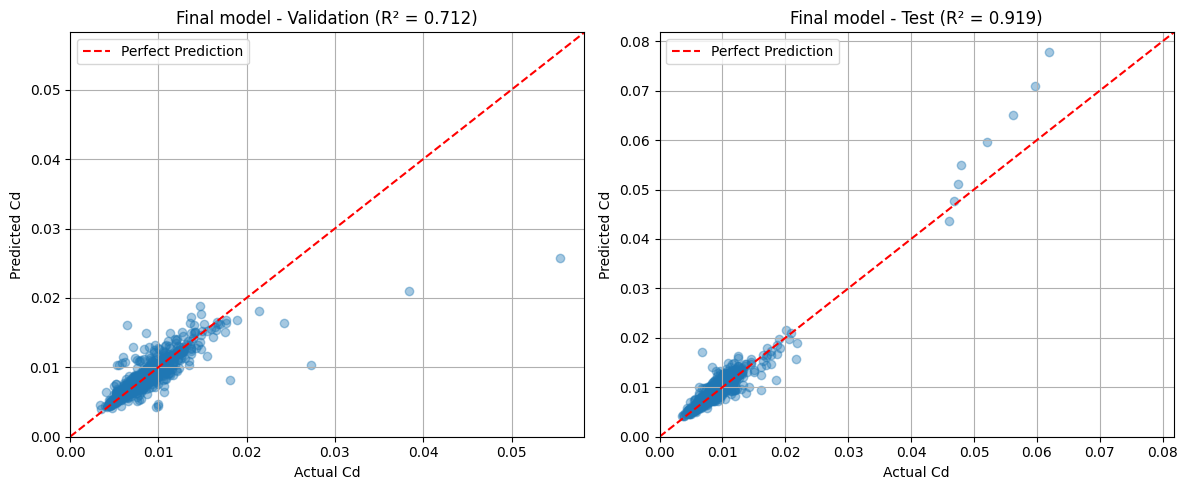

In [ ]:
# FINAL MODEL - STEP 5: TEST EVALUATION (used once)

test_pred_final = predict_final(X_test_final_scaled)
y_test_actual = y_test_1000.to_numpy()

evaluate_model("FINAL MODEL TEST RESULTS", y_test_actual, test_pred_final)

# One very thick airfoil (ah93w480b, 48% thick) dominates the test set's Cd spread,
# so also report the test score without it.
not_ah93 = (test_1000["airfoil"] != "ah93w480b").to_numpy()

evaluate_model("TEST RESULTS WITHOUT ah93w480b", y_test_actual[not_ah93], test_pred_final[not_ah93])

# ACTUAL VS PREDICTED (validation and test)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, actual, predicted, title in [
    (axes[0], y_true_final, val_pred_final, "Validation"),
    (axes[1], y_test_actual, test_pred_final, "Test")
]:
    ax.scatter(actual, predicted, alpha=0.4)
    limit = max(actual.max(), predicted.max()) * 1.05
    ax.plot([0, limit], [0, limit], "r--", label="Perfect Prediction")
    ax.set_xlim(0, limit)
    ax.set_ylim(0, limit)
    ax.set_xlabel("Actual Cd")
    ax.set_ylabel("Predicted Cd")
    ax.set_title(f"Final model - {title} (R² = {r2_score(actual, predicted):.3f})")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# FINAL MODEL - STEP 6: SAVE MODELS AND PREPROCESSING

import joblib
from pathlib import Path

save_dir = Path("final_model_files")
save_dir.mkdir(exist_ok=True)

for seed, model in zip(SEEDS_FINAL, models_final):
    model.save(save_dir / f"airfoil_mlp_final_seed{seed}.keras")

joblib.dump(
    {
        "geometry_scaler": geometry_scaler_final,
        "pca": pca_final,
        "input_scaler": input_scaler_final,
        "clip_low": clip_low_final,
        "clip_high": clip_high_final,
        "log_mean": log_mean_final,
        "log_std": log_std_final,
    },
    save_dir / "preprocessing_final.pkl"
)

print("Final models and preprocessing saved to", save_dir.resolve())

Final models and preprocessing saved to C:\Users\Nikhit\Desktop\airfoil_surrogate_copy\improved_mlp\notebooks\final_model_files


**Summary:** compared with V15, the final model raises validation R² from about 0.65 to about 0.71 and lowers MAE by about 13%. The biggest difference shows up on the test set. The very thick airfoil ah93w480b is outside the training range; without the clamp, V15-style models predict nearly three times its true drag there, while the final model stays close. To predict for a new airfoil, apply the saved geometry scaler → PCA → input scaler → clamp, average the five models in log space, then take `exp()`, exactly as `make_final_inputs` and `predict_final` do above.